In [81]:
import warnings

import dask
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import seaborn as sns
import cartopy.crs as ccrs
from cmcrameri import cm

import atmicp

warnings.filterwarnings("ignore", category=FutureWarning)
# the outer join over experiments reindexes every chunk; the warning is expected
warnings.filterwarnings("ignore", category=dask.array.core.PerformanceWarning)
dask.config.set(**{'array.slicing.split_large_chunks': True})

In [82]:
atmicp.style.set_style()

# climate colours and perturbation linestyles as in notebook 08
CLIM = {'pi': atmicp.style.climate_color('1870'),        # blue
        'curr': atmicp.style.climate_color('present'),   # grey
        'incr': atmicp.style.climate_color('future1')}   # orange

LABEL = {'pi': 'pre-industrial', 'curr': 'current', 'incr': 'increased'}

LS = {'iterated': '-.', 'iterated_short': ':', 'tq': '--', 'ocean': '-',
      'none': '-'}

PERT_LABEL = {'iterated': 'iterated', 'iterated_short': 'iterated, short',
              'tq': 'ERA5 delta', 'ocean': 'ocean only', 'none': 'unperturbed'}

# markers where linestyle already separates land from ocean
MARKER = {'iterated': 'o', 'iterated_short': 's', 'none': '^'}

DIVERGING = cm.vik

In [83]:
SCALE = {'t': 1.0, 'q': 1e6}  # q in mg/kg, avoids 1e-6 axis offsets
SYMBOL = {'t': 'T', 'q': 'q'}
UNITS = {'t': 'K', 'q': r'mg kg$^{-1}$'}

# deltas are always warmer minus cooler
WARMTH = {'pi': 0, 'curr': 1, 'incr': 2}

# Ignore poles, definition of tropics
LAT_LIMIT = 60
TROPICS_LIMIT = 23.5

# Land sea mask
lsm = atmicp.Data.get_lsm(res='GLO100')

BANDS = {
    'extratropics': lambda lat: (np.abs(lat) > TROPICS_LIMIT) & (np.abs(lat) <= LAT_LIMIT),
    'tropics': lambda lat: np.abs(lat) <= TROPICS_LIMIT,
    'global': lambda lat: np.abs(lat) <= LAT_LIMIT,
}
SURFACES = ['land', 'ocean', 'all']

In [84]:
def land_ocean_stats(da):
    """cos(lat)-weighted mean, std and mean |delta| over land, ocean and global, within LAT_LIMIT."""
    da = da.isel(latitude=np.abs(da.latitude.values) <= LAT_LIMIT)
    mask = lsm.sel(latitude=da.latitude, longitude=da.longitude)

    masks = {'land': mask > 0.5, 'ocean': mask <= 0.5,
             'global': xr.ones_like(mask, dtype=bool)}
    coslat = np.cos(np.deg2rad(da.latitude))
    dims = ('latitude', 'longitude')

    stats = []
    for m in masks.values():
        w = (coslat * m).astype(float)
        stats.append(xr.concat([da.weighted(w).mean(dims),
                                da.weighted(w).std(dims),
                                np.abs(da).weighted(w).mean(dims)],
                               dim=pd.Index(['mean', 'std', 'absmean'], name='stat')))

    return xr.concat(stats, dim=pd.Index(list(masks), name='region'))


def band_surface_mean(da):
    """cos(lat)-weighted mean per latitude band (BANDS) and surface (SURFACES), members kept."""
    da = da.isel(latitude=np.abs(da.latitude.values) <= LAT_LIMIT)
    lat = da.latitude
    mask = lsm.sel(latitude=lat, longitude=da.longitude)

    masks = {'land': mask > 0.5, 'ocean': mask <= 0.5,
             'all': xr.ones_like(mask, dtype=bool)}
    coslat = np.cos(np.deg2rad(lat))

    # one dask graph for every band and surface, so the fields are read once
    return xr.concat(
        [xr.concat([da.weighted((coslat * in_band(lat) * masks[surface]).astype(float))
                      .mean(('latitude', 'longitude'))
                    for surface in SURFACES],
                   dim=pd.Index(SURFACES, name='surface'))
         for in_band in BANDS.values()],
        dim=pd.Index(list(BANDS), name='band'))

In [85]:
def delta(ds, climates, perturbations, ref=('curr', 'none'), var='t', time=0,
          keep_members=False):
    """Each of `climates` x `perturbations` against `ref` at lead `time`, warmer minus cooler.

    q in mg/kg (SCALE). `keep_members` skips the member mean.
    """
    climates, perturbations = list(climates), list(perturbations)
    a = ds[var].sel(climate=climates, perturbation=perturbations)
    b = ds[var].sel(climate=ref[0], perturbation=ref[1], drop=True)

    # flip climates cooler than ref; within one climate the order is left as given
    sign = xr.DataArray([-1 if WARMTH[c] < WARMTH[ref[0]] else 1 for c in climates],
                        coords={'climate': climates}, dims='climate')

    d = (sign * (a - b)).sel(time=time)
    if not keep_members:
        d = d.mean('number')
    d = d * SCALE.get(var, 1.0)
    d.attrs = {'ref_expver': ref, 'var': var, 'time': time,
               'long_name': fr'$\Delta${SYMBOL.get(var, var)}',
               'units': UNITS.get(var, ds[var].attrs.get('units', ''))}
    return d

In [86]:
def delta_full(ds, climates=None, perturbations=None, ref=('curr', 'none'), var='t',
               keep_members=False):
    """Each of `climates` x `perturbations` against `ref` at every valid time, warmer minus cooler.

    Defaults to every climate and perturbation in `ds` other than `ref`.
    """
    if climates is None:
        climates = [c for c in ds.climate.values if c != ref[0]]
    if perturbations is None:
        perturbations = [p for p in ds.perturbation.values if p != ref[1]]
    climates, perturbations = list(climates), list(perturbations)
    a = ds[var].sel(climate=climates, perturbation=perturbations)
    b = ds[var].sel(climate=ref[0], perturbation=ref[1], drop=True)

    # flip climates cooler than ref; within one climate the order is left as given
    sign = xr.DataArray([-1 if WARMTH[c] < WARMTH[ref[0]] else 1 for c in climates],
                        coords={'climate': climates}, dims='climate')

    d = sign * (a - b)
    if not keep_members:
        d = d.mean('number')
    d = d * SCALE.get(var, 1.0)
    d.attrs = {'ref_expver': ref, 'var': var,
               'long_name': fr'$\Delta${SYMBOL.get(var, var)}',
               'units': UNITS.get(var, ds[var].attrs.get('units', ''))}
    return d

In [87]:
def band_figure(drift, adj, name):
    """3 x 3 band-by-surface grid of drift (iterations) and adjustment (full simulations).

    Line: ensemble mean; shading: member range; dashed: initialisations of `adj`.
    """
    fig, axes = plt.subplots(len(BANDS), len(SURFACES),
                             figsize=(1.5 * atmicp.style.REF_WIDTH,
                                      1.35 * atmicp.style.REF_WIDTH),
                             sharex=True, sharey=True)

    # type sizes are quoted at REF_WIDTH, scale them to this canvas
    fs_title = atmicp.style.scaled(atmicp.style.FS_TITLE, fig)
    fs_label = atmicp.style.scaled(atmicp.style.FS_LABEL, fig)
    fs_tick = atmicp.style.scaled(atmicp.style.FS_TICK, fig)
    fs_annot = atmicp.style.scaled(atmicp.style.FS_ANNOT, fig)
    fs_header = atmicp.style.scaled(atmicp.style.FS_HEADER, fig)

    for r, band in enumerate(BANDS):
        for c, surface in enumerate(SURFACES):
            ax = axes[r, c]
            for climate, pert in FIG_SERIES:
                sel = dict(band=band, surface=surface, climate=climate, perturbation=pert)
                # the iterations, then one full simulation per initialisation
                for s in [drift[name].sel(**sel)] + [adj[name].sel(**sel, inidate=inidate)
                                                     for inidate in adj.inidate.values]:
                    # sfc and pl share the time axis but not the output steps
                    s = s.dropna('time', how='all')
                    ax.fill_between(s.time.values, s.min('number'), s.max('number'),
                                    color=CLIM[climate], alpha=0.25, linewidth=0, zorder=1)
                    ax.plot(s.time.values, s.mean('number'), color=CLIM[climate],
                            linestyle=LS[pert], linewidth=1.1, zorder=2)

            ax.axhline(0, color=atmicp.style.MUTED, linewidth=0.6, zorder=0)
            for inidate in adj.inidate.values:
                ax.axvline(inidate, color=atmicp.style.MUTED, linestyle='--',
                           linewidth=0.8, zorder=0)
            ax.set_ylabel(AXIS_LABEL[name] if c == 0 else '', fontsize=fs_label)
            ax.set_xlabel('date' if r == len(BANDS) - 1 else '', fontsize=fs_label)
            ax.tick_params(axis='both', which='major', labelsize=fs_tick,
                           bottom=True, left=True, direction='out',
                           length=atmicp.style.scaled(3.5, fig),
                           width=atmicp.style.scaled(0.8, fig),
                           color=atmicp.style.INK)
            if r == 0:
                ax.set_title(SURFACE_TITLE[surface], fontsize=fs_title)

        axes[r, -1].annotate(BAND_ROW_LABEL[band], xy=(1.04, 0.5),
                             xycoords='axes fraction', rotation=270,
                             va='center', ha='left', fontsize=fs_header,
                             fontweight='bold', color=atmicp.style.MUTED)

    sns.despine(fig=fig)

    for ax in axes.flatten():
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    for ax in axes[-1, :]:
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    atmicp.style.panel_labels(axes.flatten())

    fig.suptitle(f'{FIG_TITLE[name]}, delta against b2ut, warming direction',
                 fontsize=fs_title, fontweight='bold')
    fig.tight_layout(rect=[0, 0.13, 1, 0.98])

    fig.legend(handles=[mlines.Line2D([], [], color=CLIM[climate], linestyle=LS[pert],
                                      label=f'{LABEL[climate]}, {PERT_LABEL[pert]}')
                        for climate, pert in FIG_SERIES],
               loc='upper left', bbox_to_anchor=(0.06, 0.12), ncol=2,
               frameon=False, fontsize=fs_annot, title='Experiment',
               title_fontproperties={'weight': 'bold', 'size': fs_annot})

    fig.legend(handles=[mpatches.Patch(color='0.45', alpha=0.4, linewidth=0,
                                       label='member range')],
               loc='upper right', bbox_to_anchor=(0.94, 0.12), frameon=False,
               fontsize=fs_annot)

    atmicp.style.save(fig, f'12_adjustment_bands_{name}', dpi=300)
    return fig

In [88]:
ITER = atmicp.data.RUN_SETS['iterated']

# the iterative experiments, plus the unperturbed run they are differenced against
EXPVERS = {expver: (climate, ITER['perturbation'][expver])
           for climate, expvers in ITER['expver'].items() for expver in expvers
           if ITER['perturbation'][expver] in ('iterated', 'iterated_short', 'none')}

# Load data

In [89]:
ifs_sfc = atmicp.Data.get_ifs_data(levtype='sfc', res='GLO100', variables=['t2m', 'tcwv'], sst=False)
ifs_pl = atmicp.Data.get_ifs_data(levtype='pl', res='GLO100', variables=['t'], sst=False)

Loading 3 file(s) for b2vj (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/cf
Loading 3 file(s) for b2vj (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/pf
Loading 3 file(s) for b2vr (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/cf
Loading 3 file(s) for b2vr (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/pf
Loading 3 file(s) for b2vl (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/cf
Loading 3 file(s) for b2vl (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/sfc/pf
Loading 3 file(s) for b2ut (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/sfc/cf


/home/e/ermis/ATMICP/atmicp/data.py:198: UserWarning: No files found for b2vo (pi, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(


Loading 3 file(s) for b2ut (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/sfc/pf
Loading 3 file(s) for b2vk (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/cf
Loading 3 file(s) for b2vk (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/pf
Loading 3 file(s) for b2vq (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/cf
Loading 3 file(s) for b2vq (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/pf
Loading 3 file(s) for b2vm (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/cf
Loading 3 file(s) for b2vm (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/sfc/pf
Loading 3 file(s) for b2vj (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf


/home/e/ermis/ATMICP/atmicp/data.py:198: UserWarning: No files found for b2vn (incr, GLO100, sfc) on the requested inidates - skipping this experiment.
  warnings.warn(


Loading 3 file(s) for b2vj (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vr (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vr (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vl (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vl (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2vo (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/cf
Loading 3 file(s) for b2vo (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/pi/GLO100/pl/pf
Loading 3 file(s) for b2ut (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/pl/cf
Loading 3 file(s) for b2ut (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/curr/GLO100/pl/pf
Loading 3 file(s) for b2vk (cf) from /gf5/

/home/e/ermis/ATMICP/atmicp/data.py:263: UserWarning: b2vq: missing inidates ['b2vq_2021-06-22.nc', 'b2vq_2021-06-26.nc'] in /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/cf
  warnings.warn(
/home/e/ermis/ATMICP/atmicp/data.py:263: UserWarning: b2vq: missing inidates ['b2vq_2021-06-22.nc', 'b2vq_2021-06-26.nc'] in /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf
  warnings.warn(


Loading 3 file(s) for b2vm (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf
Loading 3 file(s) for b2vn (cf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/cf
Loading 3 file(s) for b2vn (pf) from /gf5/predict/AWH019_ERMIS_ATMICP/ITERATION/MED-R/EXP/incr/GLO100/pl/pf


In [90]:
# short simulations of IFS iterations
ifs_iter_pl = atmicp.data.Data.load_iterations(levtype='pl')
ifs_iter_sfc = atmicp.data.Data.load_iterations(levtype='sfc')

# Process into one dataframe

In [91]:
EXPVERS

{'b2vj': ('pi', 'iterated'),
 'b2vr': ('pi', 'iterated_short'),
 'b2ut': ('curr', 'none'),
 'b2vk': ('incr', 'iterated'),
 'b2vq': ('incr', 'iterated_short')}

In [92]:
REGION_LS = {'land': '-', 'ocean': '--'}

CLIMATES = ['pi', 'incr']
PERTS = ['iterated', 'iterated_short']

# dims: stat, region, climate, perturbation, inidate, number
drift_sfc = xr.Dataset({var: land_ocean_stats(delta(ifs_iter_sfc, CLIMATES, PERTS, var=var, keep_members=True))
                    for var in ['t2m', 'tcwv']}).compute()
drift_sfc = drift_sfc.drop('time').rename({'inidate': 'time'}) # rename inidate dimension to time so I can merge with the full sims

drift_pl = xr.Dataset({var: land_ocean_stats(delta(ifs_iter_pl, CLIMATES, PERTS, var=var, keep_members=True))
                    for var in ['t']}).compute()
drift_pl = drift_pl.drop('time').rename({'inidate': 'time'})

In [93]:
# land ocean stats for long simulations, every perturbation against curr/none
adjustment_sfc = xr.Dataset({var: land_ocean_stats(delta_full(ifs_sfc, var=var, keep_members=True))
                    for var in ['t2m', 'tcwv']}).compute()

adjustment_pl = xr.Dataset({var: land_ocean_stats(delta_full(ifs_pl, var=var, keep_members=True))
                    for var in ['t']}).compute()

In [94]:
adj = adjustment_sfc.sel(inidate='2021-06-26', drop=True).dropna('time', how='all')
drift = drift_sfc.sel(time=drift_sfc.time < adj.time[0])  # avoid duplicate 06-26
sfc = xr.concat([drift, adj], dim='time', join='outer').sortby('time')

adj = adjustment_pl.sel(inidate='2021-06-26', drop=True).dropna('time', how='all')
drift = drift_pl.sel(time=drift_pl.time < adj.time[0])  # avoid duplicate 06-26
pl = xr.concat([drift, adj], dim='time', join='outer').sortby('time')


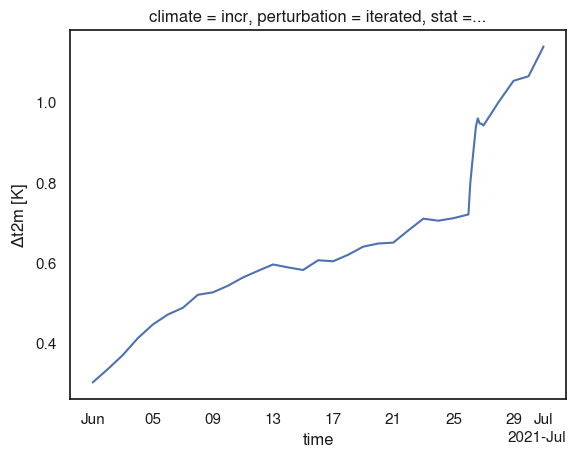

In [78]:
sfc.t2m.sel(stat='mean', region='land', climate='incr', perturbation='iterated').mean('number').plot()

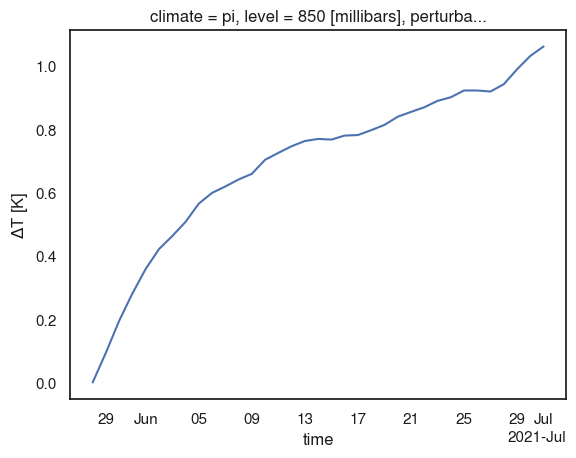

In [80]:
pl.t.sel(stat='mean', region='land', climate='pi', perturbation='iterated', level=850).mean('number').plot()

# Drift and adjustment by latitude band and surface

In [97]:
FIG_PERTS = ['iterated', 'iterated_short', 'tq']
FIG_LEVELS = [1000, 850, 500]
FIG_SERIES = [(climate, pert) for climate in CLIMATES for pert in FIG_PERTS]

# iterations at initialisation, inidate becomes the time axis
drift_bands = xr.Dataset(
    {var: delta(ifs_iter_sfc, CLIMATES, PERTS, var=var, keep_members=True)
     for var in ['t2m', 'tcwv']}
    | {f't{lev}': delta(ifs_iter_pl, CLIMATES, PERTS, var='t', keep_members=True)
                  .sel(level=lev, drop=True)
       for lev in FIG_LEVELS})
drift_bands = band_surface_mean(drift_bands).compute()
# tq has no iterations, padded with NaN so every series selects
drift_bands = (drift_bands.drop_vars('time').rename({'inidate': 'time'})
               .reindex(perturbation=FIG_PERTS))

# full simulations from every initialisation, every valid time
adj_bands = xr.Dataset(
    {var: delta_full(ifs_sfc, CLIMATES, FIG_PERTS, var=var, keep_members=True)
     for var in ['t2m', 'tcwv']}
    | {f't{lev}': delta_full(ifs_pl.sel(level=lev, drop=True), CLIMATES, FIG_PERTS,
                             var='t', keep_members=True)
       for lev in FIG_LEVELS})
adj_bands = band_surface_mean(adj_bands).compute().dropna('time', how='all')

In [98]:
BAND_ROW_LABEL = {'extratropics': 'EXTRATROPICS', 'tropics': 'TROPICS',
                  'global': 'GLOBAL'}
SURFACE_TITLE = {'land': 'land', 'ocean': 'ocean', 'all': 'land and ocean'}

AXIS_LABEL = {'t2m': r'$\Delta$T$_{2m}$ / K', 'tcwv': r'$\Delta$TCWV / kg m$^{-2}$'}
AXIS_LABEL |= {f't{lev}': rf'$\Delta$T$_{{{lev}}}$ / K' for lev in FIG_LEVELS}
FIG_TITLE = {'t2m': '2 m temperature', 'tcwv': 'Total column water vapour'}
FIG_TITLE |= {f't{lev}': f'Temperature at {lev} hPa' for lev in FIG_LEVELS}

for name in drift_bands.data_vars:
    band_figure(drift_bands, adj_bands, name)
plt.show()

TypeError: band_figure() takes 2 positional arguments but 3 were given